# 12. Bias–Variance Tradeoff

As model complexity grows, training score often rises, but CV score may stall or drop.
We show this with three knobs:
- Decision Tree: `max_depth` (larger → more complex)
- k-NN: `n_neighbors` (smaller → more complex)
- Polynomial regression: `degree` (larger → more complex)

In [ ]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

from src.data import load_adult
from src.preprocess import split_features_target, make_model_pipeline
from src.evaluate import ThresholdingRegressor, N_SPLITS, RANDOM_STATE

X, y = split_features_target(load_adult("train"))
print(X.shape, y.mean())

(32561, 12) 0.2408095574460244


In [11]:
def train_cv_curves(pipes_by_label, X, y, scoring="f1"):

    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    labels, train_means, cv_means = [], [], []

    for label, pipe in pipes_by_label.items():
        raw = cross_validate(
            pipe, X, y, 
            cv = cv, 
            scoring=scoring,
            return_train_score=True,
            n_jobs=-1,
        )
        labels.append(label)
        train_means.append(raw["train_score"].mean())
        cv_means.append(raw["test_score"].mean())
        print(f"{label}: train={train_means[-1]:.4f}, cv={cv_means[-1]:.4f}")
    return labels, train_means, cv_means

def plot_tradeoff(labels, train_means, cv_means, title, xlabel):
    xs = np.arange(len(labels))
    plt.figure(figsize=(7, 4))
    plt.plot(xs, train_means, marker="o", label="Train")
    plt.plot(xs, cv_means, marker="o", label="CV")
    plt.xticks(xs, labels)
    plt.xlabel(xlabel)
    plt.ylabel("F1")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


2: train=0.5568, cv=0.5568
5: train=0.6233, cv=0.6200
10: train=0.6913, cv=0.6579
15: train=0.7802, cv=0.6668
None: train=0.9549, cv=0.6204


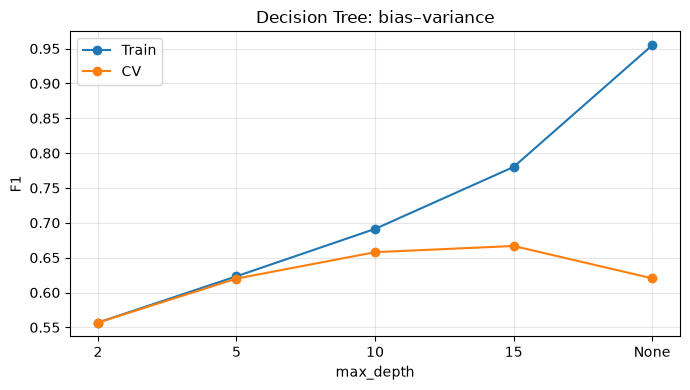

In [12]:
depths = [2, 5, 10, 15, None]
tree_pipes = {
    str(d): make_model_pipeline(
        DecisionTreeClassifier(max_depth=d, random_state=42),
        scale=False,
    )
    for d in depths
}

labels, tr, cv = train_cv_curves(tree_pipes, X, y, scoring="f1")
plot_tradeoff(labels, tr, cv, "Decision Tree: bias–variance", "max_depth")

3: train=0.7801, cv=0.6314
5: train=0.7430, cv=0.6406
15: train=0.6978, cv=0.6624
35: train=0.6850, cv=0.6698
51: train=0.6796, cv=0.6686


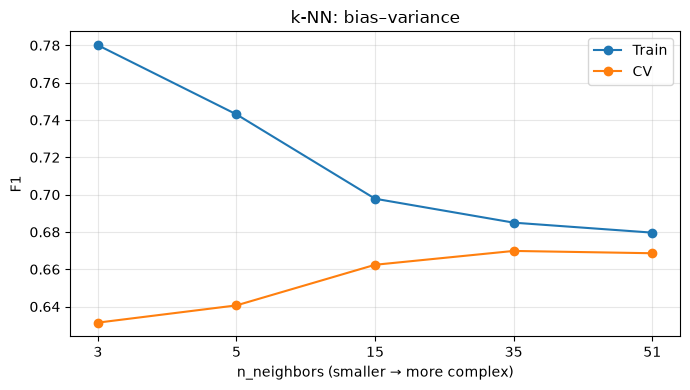

In [14]:
ks = [3, 5, 15, 35, 51]
knn_pipes = {
    str(k): make_model_pipeline(KNeighborsClassifier(n_neighbors=k, n_jobs=-1))
    for k in ks
}

labels, tr, cv = train_cv_curves(knn_pipes, X, y, scoring="f1")
plot_tradeoff(labels, tr, cv, "k-NN: bias–variance", "n_neighbors (smaller → more complex)")

1: train=0.6253, cv=0.6236
2: train=0.6881, cv=0.6594


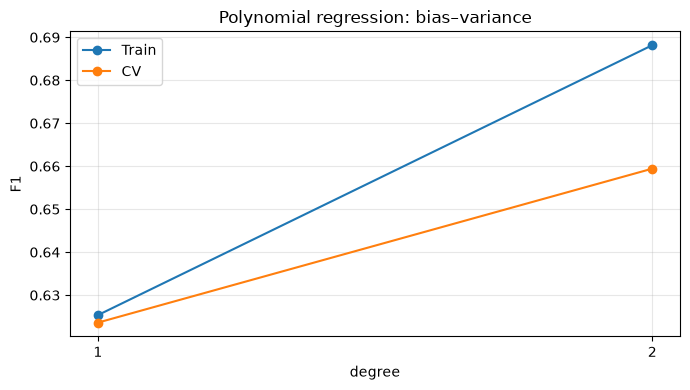

In [13]:
def make_poly_pipe(degree):
    inner = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("reg", LinearRegression()),
    ])
    return make_model_pipeline(ThresholdingRegressor(inner))

degrees = [1, 2]
poly_pipes = {str(d): make_poly_pipe(d) for d in degrees}

labels, tr, cv = train_cv_curves(poly_pipes, X, y, scoring="f1")
plot_tradeoff(labels, tr, cv, "Polynomial regression: bias–variance", "degree")